# Is a Social Circle Also a Music Circle?
### Community detection on the LastFM Asia network

**STAT 236, Fall 2026. Faye Fang and Grace Chen.**

We ask whether users in the same network community also share music taste.

1. **Community structure:** What communities do we find using only the follow network?
2. **Social circle and music circle:** Are users in the same community more similar in music taste than users in different communities?
3. **Country:** Is this only because people from the same country like the same music?
4. **Method choice:** Does the answer change across Spectral, SCORE, SCORE+ and Louvain?

**Main rule of the design.** The network is used to form communities. Music and country are used only to test them. They are never used to fit a method or choose a parameter.

This one notebook creates every table and figure. Everything is saved in `output/`.

## 0. Setup

In [1]:
import hashlib, json, os, random, time
from pathlib import Path

os.environ.setdefault('MPLBACKEND', 'module://matplotlib_inline.backend_inline')
import igraph as ig
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
import networkx as nx
import numpy as np
import pandas as pd
from scipy import sparse as sp
from scipy.optimize import linear_sum_assignment
from scipy.sparse.linalg import eigsh
from sklearn.cluster import KMeans
from sklearn.metrics import normalized_mutual_info_score as NMI
from threadpoolctl import threadpool_limits

threadpool_limits(limits=4)

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / 'data').is_dir())
DATA = ROOT / 'data'

# A quick run checks that the code works. Its results are not used in the report.
QUICK = os.environ.get('STAT236_QUICK') == '1'
OUT = ROOT / ('tmp/quick_output' if QUICK else 'output')
FIG, TAB = OUT / 'figures', OUT / 'tables'
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

SEED = 236
B_MAIN = 9 if QUICK else 1999    # permutations for the main test
B_CHECK = 5 if QUICK else 199    # permutations for country and sensitivity checks
N_SUB = 2 if QUICK else 10       # edge-deletion runs used when choosing K
N_INIT = 20                      # k-means random starts
K_RANGE = range(3, 21)
T_RULE = 0.1                     # SCORE+ weak-signal threshold

METHODS = ['Spectral', 'SCORE', 'SCORE+', 'Louvain']
UNCLIPPED = 'SCORE+ (no clipping)'
COLOR = dict(zip(METHODS, ['#426B8A', '#278A80', '#8C79A8', '#CB735F']))
MARKER = dict(zip(METHODS, ['o', 's', 'D', '^']))
INK, MUTED, NEUTRAL = '#253746', '#697582', '#BCC6CF'

mpl.rcParams.update({
    'font.family': 'STIXGeneral', 'font.size': 8.8, 'mathtext.fontset': 'stix',
    'axes.labelsize': 8.8, 'axes.titlesize': 9.6,
    'xtick.labelsize': 8, 'ytick.labelsize': 8, 'legend.fontsize': 8,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#9DA8B2', 'axes.linewidth': .6,
    'axes.labelcolor': INK, 'text.color': INK,
    'xtick.color': MUTED, 'ytick.color': MUTED,
    'xtick.major.size': 2.5, 'ytick.major.size': 2.5,
    'axes.axisbelow': True, 'pdf.fonttype': 42, 'savefig.facecolor': 'white',
    'figure.dpi': 130,
})

def save_figure(fig, name):
    for ext in ['pdf', 'png']:
        fig.savefig(FIG / f'{name}.{ext}', dpi=300, bbox_inches='tight', pad_inches=.06)

def save_table(frame, name, index=False):
    frame.to_csv(TAB / f'{name}.csv', index=index, float_format='%.12g')

def panel_title(ax, letter, heading):
    ax.set_title(f'({letter})  {heading}', loc='left', fontweight='bold', pad=9)

def y_grid(ax):
    ax.grid(False)
    ax.grid(axis='y', color='#E8ECF0', lw=.55)

def x_grid(ax):
    ax.grid(False)
    ax.grid(axis='x', color='#E8ECF0', lw=.55)

def method_legend(fig, y=.005):
    handles = [Line2D([], [], marker=MARKER[m], color=COLOR[m], lw=1.3, ms=4, label=m) for m in METHODS]
    fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(.5, y), ncol=4,
               frameon=False, columnspacing=2.6, handlelength=1.8)

print('Output folder:', OUT.relative_to(ROOT), '| main permutations:', B_MAIN, '| check permutations:', B_CHECK)

Output folder: output | main permutations: 1999 | check permutations: 199


## 1. Data and cleaning

Users are nodes and mutual follows are edges. Each user also has a list of liked artists and a country. Artists and countries are anonymous.

Cleaning has three steps:

1. Check for self-loops and duplicate edges.
2. Remove users with no music data, because we cannot test them.
3. Keep the largest connected component. In a connected network every entry of the first eigenvector is positive, so SCORE never divides by zero.

In [2]:
edges_raw = pd.read_csv(DATA / 'lastfm_edges.csv')
edges_raw.columns = ['u', 'v']
target = pd.read_csv(DATA / 'lastfm_target.csv')
target.columns = ['node_id', 'country']
likes_raw = pd.read_csv(DATA / 'lastfm_features.csv').rename(columns={'feature_id': 'artist_id'})[['node_id', 'artist_id']]

canon = np.sort(edges_raw[['u', 'v']].values, axis=1)
n_self = int((edges_raw.u == edges_raw.v).sum())
n_dup = int(pd.DataFrame(canon).duplicated().sum())

G_full = nx.Graph()
G_full.add_nodes_from(target.node_id)
G_full.add_edges_from(canon[canon[:, 0] != canon[:, 1]])
music_users = set(likes_raw.node_id.unique())
G_music = G_full.subgraph([v for v in G_full if v in music_users])
G = G_music.subgraph(max(nx.connected_components(G_music), key=len)).copy()

nodes = np.array(sorted(G.nodes()))
n = len(nodes)
idx = {v: i for i, v in enumerate(nodes)}
A = nx.to_scipy_sparse_array(G, nodelist=nodes, format='csr').astype(np.float64)
deg = np.asarray(A.sum(1)).ravel()
country = target.set_index('node_id').loc[nodes, 'country'].values

lk = likes_raw.drop_duplicates()
lk = lk[lk.node_id.isin(idx)]
X = sp.csr_matrix((np.ones(len(lk), dtype=np.float32), (lk.node_id.map(idx).values, lk.artist_id.values)),
                  shape=(n, int(likes_raw.artist_id.max()) + 1))
X = X[:, np.asarray(X.sum(0)).ravel() > 0].tocsr()
n_art = np.asarray(X.sum(1)).ravel()
art_pop = np.asarray(X.sum(0)).ravel()
rho = pd.Series(deg).corr(pd.Series(n_art), method='spearman')

assert nx.is_connected(G) and np.all(deg > 0) and np.all(n_art > 0)
assert (A != A.T).nnz == 0 and np.all(A.diagonal() == 0)

data_summary = pd.DataFrame([
    ('Users (raw)', G_full.number_of_nodes()),
    ('Edges (raw)', len(edges_raw)),
    ('Self-loops', n_self),
    ('Duplicate edges', n_dup),
    ('Users without music data', G_full.number_of_nodes() - len(music_users & set(G_full))),
    ('Components after removing them', nx.number_connected_components(G_music)),
    ('Users in final sample', n),
    ('Edges in final sample', G.number_of_edges()),
    ('Artists in final sample', X.shape[1]),
    ('Mean degree', deg.mean()),
    ('Median degree', np.median(deg)),
    ('Max degree', deg.max()),
    ('Mean artists per user', n_art.mean()),
    ('Median artists per user', np.median(n_art)),
    ('Min users per artist', art_pop.min()),
    ('Countries', len(np.unique(country))),
    ('Spearman correlation of degree and artists', rho),
], columns=['Quantity', 'Value'])
save_table(data_summary, 'data_summary')
data_summary

,Quantity,Value
0,Users (raw),7624.000000
1,Edges (raw),27806.000000
2,Self-loops,0.000000
3,Duplicate edges,0.000000
4,Users without music data,173.000000
5,Components after removing them,18.000000
6,Users in final sample,7431.000000
7,Edges in final sample,27045.000000
8,Artists in final sample,7842.000000
9,Mean degree,7.278966


## 2. The four methods

All four methods use the network only. They differ in how they deal with the large gaps in degree.

- **Spectral:** run k-means on the first K eigenvectors of A.
- **SCORE:** divide eigenvectors 2 to K by eigenvector 1 entry by entry, clip the ratios to ±log n, then run k-means.
- **SCORE+:** replace A with a regularized matrix L_τ, weight each eigenvector by its eigenvalue, take ratios, clip them to ±log n, then run k-means. If the signal looks weak, it uses one extra eigenvector.
- **Louvain:** do not use eigenvectors. Move users between groups to increase modularity.

Clipping is our change to the SCORE+ algorithm of Jin, Ke and Luo. It follows the threshold in the SCORE paper (Jin, 2015) and keeps the rule the same as for SCORE. We also report results without clipping.

In [3]:
def leading_eigs(matrix, k, seed=SEED):
    # Eigenpairs sorted by size. The first vector is refined so that it stays positive,
    # because tiny entries in this vector decide how accurate the ratios are.
    matrix = sp.csr_matrix(matrix, dtype=np.float64)
    vals, vecs = eigsh(matrix, k=k, which='LM', v0=np.random.default_rng(seed).normal(size=matrix.shape[0]), tol=1e-11)
    order = np.argsort(-np.abs(vals), kind='stable')
    vals, vecs = vals[order], vecs[:, order]
    v = np.full(matrix.shape[0], 1 / np.sqrt(matrix.shape[0]))
    shift = abs(vals[0])
    for _ in range(20000):
        w = matrix @ v + shift * v
        w /= np.linalg.norm(w)
        relative = np.max(np.abs(w - v) / np.maximum(w, np.finfo(float).tiny))
        v = w
        if relative < 1e-10:
            break
    else:
        raise RuntimeError('Leading eigenvector did not converge')
    perron = int(np.argmax(vals))
    vecs[:, perron] = v
    vals[perron] = float(v @ (matrix @ v))
    order = [perron] + [j for j in range(k) if j != perron]
    return vals[order], vecs[:, order]

def reg_laplacian(adjacency, tau):
    d = np.asarray(adjacency.sum(axis=1)).ravel()
    scale = sp.diags(1 / np.sqrt(d + tau))
    return (scale @ adjacency @ scale).tocsr()

def relabel_by_size(labels):
    _, inverse, counts = np.unique(labels, return_inverse=True, return_counts=True)
    rank = np.empty_like(counts)
    rank[np.argsort(-counts, kind='stable')] = np.arange(len(counts))
    return rank[inverse]

def kmeans(embedding, k, seed=SEED):
    return relabel_by_size(KMeans(k, n_init=N_INIT, random_state=seed, algorithm='lloyd').fit_predict(embedding))

def score_ratios(vecs, k, clip=True):
    ratios = vecs[:, 1:k] / vecs[:, [0]]
    return np.clip(ratios, -np.log(len(vecs)), np.log(len(vecs))) if clip else ratios

def scoreplus_M(vals, k, t=T_RULE):
    return k + 1 if 1 - vals[k] / vals[k - 1] <= t else k

def spectral_labels(vecs, k):
    return kmeans(vecs[:, :k], k)

def score_labels(vecs, k):
    return kmeans(score_ratios(vecs, k), k)

def scoreplus_labels(vals, vecs, k, clip=True):
    m = scoreplus_M(vals, k)
    return kmeans(score_ratios(vecs[:, :m] * vals[:m], m, clip=clip), k)

def louvain_labels(graph, resolution, seed=SEED):
    groups = nx.community.louvain_communities(graph, resolution=resolution, seed=seed)
    position = {v: i for i, v in enumerate(nodes)}
    labels = np.empty(len(nodes), dtype=int)
    for k, group in enumerate(groups):
        labels[[position[v] for v in group]] = k
    return relabel_by_size(labels)

## 3. The first eigenvector is concentrated on a few users

This check needs only A and L_τ. It does not depend on K, because the first eigenvector is the same for every K.

We use τ equal to the mean degree, and also try the value 0.1 × max degree from the SCORE+ paper.

In [4]:
TAU = deg.mean()
LOG_N = np.log(n)
vals_A, vecs_A = leading_eigs(A, 30)
L = reg_laplacian(A, TAU)
vals_L, vecs_L = leading_eigs(L, 30)
vals_max, vecs_max = leading_eigs(reg_laplacian(A, .1 * deg.max()), 30)
assert np.all(vecs_A[:, 0] > 0) and np.all(vecs_L[:, 0] > 0)

def first_vector_row(name, vec):
    return {'Matrix': name,
            'Top-50 mass of first eigenvector': np.sort(vec ** 2)[::-1][:50].sum(),
            'n sum xi^4': n * (vec ** 4).sum(),
            'Smallest entry': vec.min(),
            'Largest entry': vec.max()}

first_vector = pd.DataFrame([first_vector_row('A', vecs_A[:, 0]),
                             first_vector_row('L_tau, tau = mean degree', vecs_L[:, 0]),
                             first_vector_row('L_tau, tau = 0.1 max degree', vecs_max[:, 0])])
save_table(first_vector, 'first_eigenvector')
first_vector

,Matrix,Top-50 mass of first eigenvector,n sum xi^4,Smallest entry,Largest entry
0,A,0.796688,139.426980,1.247353e-13,0.257449
1,"L_tau, tau = mean degree",0.554773,58.865046,3.058298e-08,0.164934
2,"L_tau, tau = 0.1 max degree",0.665900,81.776960,3.397247e-10,0.172550


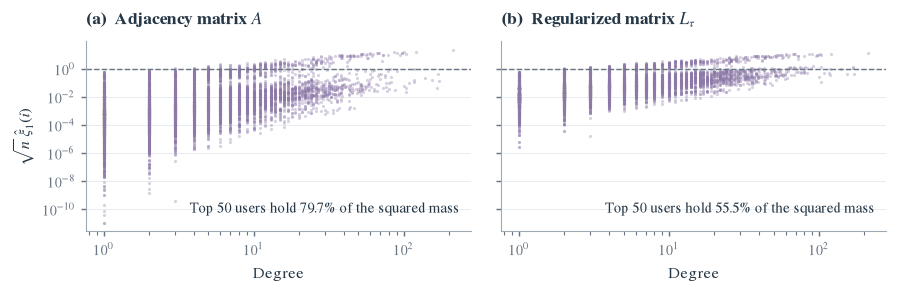

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(6.875, 2.25), sharey=True)
mass = first_vector['Top-50 mass of first eigenvector'].to_numpy()
for ax, vec, letter, heading, share in [(axs[0], vecs_A[:, 0], 'a', 'Adjacency matrix $A$', mass[0]),
                                        (axs[1], vecs_L[:, 0], 'b', r'Regularized matrix $L_\tau$', mass[1])]:
    ax.scatter(deg, vec * np.sqrt(n), s=3, color=COLOR['SCORE+'], alpha=.35, linewidths=0, rasterized=True)
    ax.axhline(1, color=MUTED, ls='--', lw=.8)
    ax.set(xscale='log', yscale='log', xlabel='Degree')
    ax.text(.97, .08, f'Top 50 users hold {share:.1%} of the squared mass', transform=ax.transAxes, ha='right', va='bottom', fontsize=8)
    panel_title(ax, letter, heading)
    y_grid(ax)
axs[0].set_ylabel(r'$\sqrt{n}\,\hat\xi_1(i)$')
fig.subplots_adjust(left=.09, right=.985, top=.85, bottom=.2, wspace=.08)
save_figure(fig, 'localization')
plt.show()

## 4. Choosing the parameters

The order matters, because some parameters depend on others.

1. **τ** is the mean degree, so L_τ is now fixed.
2. **K** is the largest relative gap between eigenvalues of L_τ, for K from 3 to 20. All methods use this K, so the comparison is fair. We also look at community sizes and at stability after deleting 10% of edges.
3. **M** is K + 1 when the gap between eigenvalues K and K + 1 is at most 0.1. This is the SCORE+ rule for weak signals.
4. **γ** is the Louvain resolution. We pick the value whose median community count over 5 seeds is closest to K.

None of these steps use music or country.

In [6]:
rng = np.random.default_rng(SEED)
upper_edges = np.array(sp.triu(A).nonzero()).T
subsamples = []
for _ in range(N_SUB):
    keep = upper_edges[rng.random(len(upper_edges)) < .9]
    B = sp.coo_matrix((np.ones(len(keep)), (keep[:, 0], keep[:, 1])), shape=(n, n))
    B = (B + B.T).tocsr()
    _, comp = sp.csgraph.connected_components(B, directed=False)
    cc = np.where(comp == np.bincount(comp).argmax())[0]
    Bs = B[cc][:, cc]
    subsamples.append((cc, leading_eigs(reg_laplacian(Bs, Bs.sum() / len(cc)), 25)))

rows = []
for k in K_RANGE:
    labels = scoreplus_labels(vals_L, vecs_L, k)
    stability = [NMI(labels[cc], scoreplus_labels(v, V, k)) for cc, (v, V) in subsamples]
    sizes = np.bincount(labels)
    rows.append({'K': k, 'relative_gap': 1 - abs(vals_L[k]) / abs(vals_L[k - 1]), 'M': scoreplus_M(vals_L, k),
                 'stability_NMI': np.mean(stability), 'stability_sd': np.std(stability, ddof=1),
                 'largest': sizes.max(), 'smallest': sizes.min()})
k_table = pd.DataFrame(rows)
save_table(k_table, 'k_selection')
K = int(k_table.loc[k_table.relative_gap.idxmax(), 'K'])
M = scoreplus_M(vals_L, K)
print('Selected K =', K, '| M =', M)
k_table.round(4)

Selected K = 11 | M = 12


,K,relative_gap,M,stability_NMI,stability_sd,largest,smallest
0,3,0.0154,4,0.7639,0.1489,4541,1193
1,4,0.0058,5,0.6743,0.0825,3829,670
2,5,0.0069,6,0.6800,0.0690,4014,332
3,6,0.0279,7,0.7890,0.0245,2157,327
4,7,0.0186,8,0.8190,0.0423,2151,140
5,8,0.0032,9,0.7924,0.0443,2124,138
6,9,0.0069,10,0.8538,0.0153,1885,138
7,10,0.0296,11,0.8541,0.0178,1907,138
8,11,0.0577,12,0.8263,0.0294,1892,138
9,12,0.0176,13,0.8404,0.0397,1466,127


In [7]:
rows = []
for gamma in [.05, .1, .15, .2, .25, .3, .4, .5, .7, 1.]:
    counts = [louvain_labels(G, gamma, seed=SEED + s).max() + 1 for s in range(5)]
    rows.append({'gamma': gamma, 'K_median': np.median(counts), 'K_min': min(counts), 'K_max': max(counts)})
gamma_table = pd.DataFrame(rows)
save_table(gamma_table, 'louvain_resolution')
GAMMA = float(gamma_table.loc[(gamma_table.K_median - K).abs().idxmin(), 'gamma'])
print('Selected gamma =', GAMMA)
gamma_table

Selected gamma = 0.25


,gamma,K_median,K_min,K_max
0,0.05,3.0,3,3
1,0.10,7.0,7,8
2,0.15,8.0,8,8
3,0.20,8.0,8,9
4,0.25,11.0,10,11
5,0.30,12.0,11,12
6,0.40,13.0,12,15
7,0.50,14.0,13,15
8,0.70,17.0,16,19
9,1.00,28.0,26,30


In [8]:
# How often ratios go past log n. These numbers depend on K, so they come after K is chosen.
raw_score = score_ratios(vecs_A, K, clip=False)
raw_plus = score_ratios(vecs_L[:, :M] * vals_L[:M], M, clip=False)
clip_summary = pd.DataFrame([
    {'Embedding': 'SCORE on A', 'Vectors in ratio': K - 1, 'Share above log n': np.mean(np.abs(raw_score) > LOG_N),
     'Largest absolute ratio': np.abs(raw_score).max()},
    {'Embedding': 'Unweighted ratios on L_tau', 'Vectors in ratio': K - 1,
     'Share above log n': np.mean(np.abs(score_ratios(vecs_L, K, clip=False)) > LOG_N),
     'Largest absolute ratio': np.abs(score_ratios(vecs_L, K, clip=False)).max()},
    {'Embedding': 'SCORE+ on L_tau', 'Vectors in ratio': M - 1, 'Share above log n': np.mean(np.abs(raw_plus) > LOG_N),
     'Largest absolute ratio': np.abs(raw_plus).max()},
])
save_table(clip_summary, 'clipping_summary')

# Is the problem really about low-degree users?
degree_group = pd.cut(deg, [0, 2, 5, 10, 50, np.inf], labels=['1-2', '3-5', '6-10', '11-50', '51+'])
by_degree = pd.DataFrame({
    'degree_group': degree_group,
    'scaled_xi1_A': vecs_A[:, 0] * np.sqrt(n),
    'scaled_xi1_L': vecs_L[:, 0] * np.sqrt(n),
    'share_clipped_SCORE': np.mean(np.abs(raw_score) > LOG_N, axis=1),
    'share_clipped_SCOREplus': np.mean(np.abs(raw_plus) > LOG_N, axis=1),
}).groupby('degree_group', observed=True).agg(
    users=('scaled_xi1_A', 'size'),
    median_scaled_xi1_A=('scaled_xi1_A', 'median'),
    median_scaled_xi1_L=('scaled_xi1_L', 'median'),
    share_clipped_SCORE=('share_clipped_SCORE', 'mean'),
    share_clipped_SCOREplus=('share_clipped_SCOREplus', 'mean')).reset_index()
save_table(by_degree, 'localization_by_degree')
display(clip_summary.round(4))
by_degree.round(4)

,Embedding,Vectors in ratio,Share above log n,Largest absolute ratio
0,SCORE on A,10,0.3932,62632.9734
1,Unweighted ratios on L_tau,10,0.0807,925.6909
2,SCORE+ on L_tau,11,0.0723,1096.2139


,degree_group,users,median_scaled_xi1_A,median_scaled_xi1_L,share_clipped_SCORE,share_clipped_SCOREplus
0,1-2,2849,0.0004,0.0140,0.4362,0.0690
1,3-5,1832,0.0018,0.0443,0.3814,0.0671
2,6-10,1345,0.0048,0.0844,0.3665,0.0763
3,11-50,1311,0.0200,0.2235,0.3544,0.0843
4,51+,94,0.2045,1.0259,0.2447,0.0542


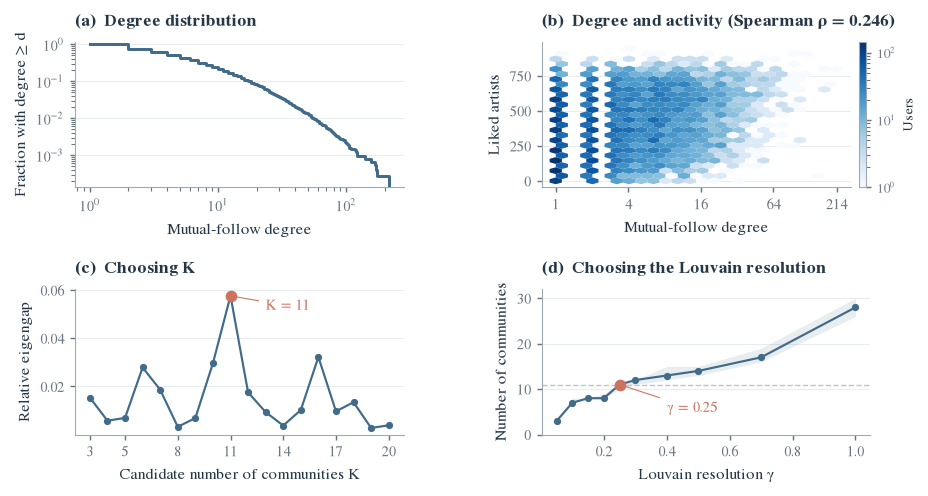

In [9]:
fig, axs = plt.subplots(2, 2, figsize=(6.875, 3.75))
d, count = np.unique(deg, return_counts=True)
axs[0, 0].step(d, np.cumsum(count[::-1])[::-1] / len(deg), where='post', color=COLOR['Spectral'], lw=1.65)
axs[0, 0].set(xscale='log', yscale='log', xlabel='Mutual-follow degree', ylabel='Fraction with degree ≥ d', ylim=(1 / len(deg), 1.15))
panel_title(axs[0, 0], 'a', 'Degree distribution')

hb = axs[0, 1].hexbin(np.log10(deg), n_art, gridsize=23, mincnt=1, bins='log', cmap='Blues', linewidths=0)
axs[0, 1].set(xlabel='Mutual-follow degree', ylabel='Liked artists', xticks=np.log10([1, 4, 16, 64, 214]), xticklabels=['1', '4', '16', '64', '214'])
cb = fig.colorbar(hb, ax=axs[0, 1], fraction=.035, pad=.025)
cb.set_label('Users', fontsize=7.5)
cb.ax.tick_params(labelsize=7)
panel_title(axs[0, 1], 'b', f'Degree and activity (Spearman ρ = {rho:.3f})')

ax = axs[1, 0]
ax.plot(k_table.K, k_table.relative_gap, '-o', color=COLOR['Spectral'], ms=3, lw=1.2)
best = k_table.loc[k_table.relative_gap.idxmax()]
ax.scatter(best.K, best.relative_gap, color=COLOR['Louvain'], s=30, zorder=4)
ax.annotate(f'K = {K}', (best.K, best.relative_gap), xytext=(13, best.relative_gap * .9), fontsize=8.2, color=COLOR['Louvain'],
            arrowprops=dict(arrowstyle='-', color=COLOR['Louvain'], lw=.6))
ax.set(xlabel='Candidate number of communities K', ylabel='Relative eigengap', xticks=[3, 5, 8, 11, 14, 17, 20])
panel_title(ax, 'c', 'Choosing K')

ax = axs[1, 1]
ax.fill_between(gamma_table.gamma, gamma_table.K_min, gamma_table.K_max, color=COLOR['Spectral'], alpha=.12, linewidth=0)
ax.plot(gamma_table.gamma, gamma_table.K_median, '-o', color=COLOR['Spectral'], ms=3, lw=1.2)
ax.axhline(K, color=NEUTRAL, ls='--', lw=.8)
ax.scatter(GAMMA, K, color=COLOR['Louvain'], s=30, zorder=4)
ax.annotate(f'γ = {GAMMA:g}', (GAMMA, K), xytext=(.40, 5), color=COLOR['Louvain'], fontsize=8.2,
            arrowprops=dict(arrowstyle='-', color=COLOR['Louvain'], lw=.6))
ax.set(xlabel='Louvain resolution γ', ylabel='Number of communities', ylim=(0, 32))
panel_title(ax, 'd', 'Choosing the Louvain resolution')
for ax in axs.flat:
    y_grid(ax)
fig.subplots_adjust(left=.085, right=.975, bottom=.115, top=.92, hspace=.70, wspace=.42)
save_figure(fig, 'study_diagnostics')
plt.show()

## 5. Final communities

In [10]:
partitions = {
    'Spectral': spectral_labels(vecs_A, K),
    'SCORE': score_labels(vecs_A, K),
    'SCORE+': scoreplus_labels(vals_L, vecs_L, K),
    'Louvain': louvain_labels(G, GAMMA),
}
extra = {UNCLIPPED: scoreplus_labels(vals_L, vecs_L, K, clip=False)}
pd.DataFrame({**partitions, **extra}, index=nodes).rename_axis('node_id').to_csv(OUT / 'partitions.csv')

size_table = pd.DataFrame({m: pd.Series(np.bincount(l)) for m, l in {**partitions, **extra}.items()})
size_table.index.name = 'community (largest first)'
save_table(size_table, 'community_sizes', index=True)

names = [*METHODS, UNCLIPPED]
all_labels = {**partitions, **extra}
nmi_table = pd.DataFrame([[NMI(all_labels[a], all_labels[b]) for b in names] for a in names], index=names, columns=names)
nmi_table['Country'] = [NMI(country, all_labels[m]) for m in names]
save_table(nmi_table, 'nmi_matrix', index=True)

hubs = deg >= np.quantile(deg, .99)
hub_table = pd.DataFrame([{
    'Method': m,
    'Share of top 1% degree users in communities below 5% of users': np.mean(np.bincount(all_labels[m])[all_labels[m][hubs]] < .05 * n),
    'Largest community share': np.bincount(all_labels[m]).max() / n,
    'Smallest community': np.bincount(all_labels[m]).min(),
    'Largest community': np.bincount(all_labels[m]).max(),
} for m in names])
save_table(hub_table, 'community_balance')
display(size_table)
display(nmi_table.round(3))
hub_table.round(3)

,Spectral,SCORE,SCORE+,Louvain,SCORE+ (no clipping)
community (largest first),,,,,
0,6830,1391,1892,1766,4651
1,99,1160,1261,1574,1297
2,71,921,1009,1096,1087
3,70,777,946,998,124
4,66,607,645,596,71
5,65,581,555,575,56
6,55,507,325,480,47
7,53,444,304,172,43
8,44,415,212,99,28


,Spectral,SCORE,SCORE+,Louvain,SCORE+ (no clipping),Country
Spectral,1.000,0.131,0.154,0.138,0.110,0.140
SCORE,0.131,1.000,0.622,0.578,0.422,0.507
SCORE+,0.154,0.622,1.000,0.636,0.497,0.524
Louvain,0.138,0.578,0.636,1.000,0.452,0.635
SCORE+ (no clipping),0.110,0.422,0.497,0.452,1.000,0.393


,Method,Share of top 1% degree users in communities below 5% of users,Largest community share,Smallest community,Largest community
0,Spectral,0.907,0.919,35,6830
1,SCORE,0.133,0.187,263,1391
2,SCORE+,0.160,0.255,138,1892
3,Louvain,0.000,0.238,13,1766
4,SCORE+ (no clipping),0.000,0.626,6,4651


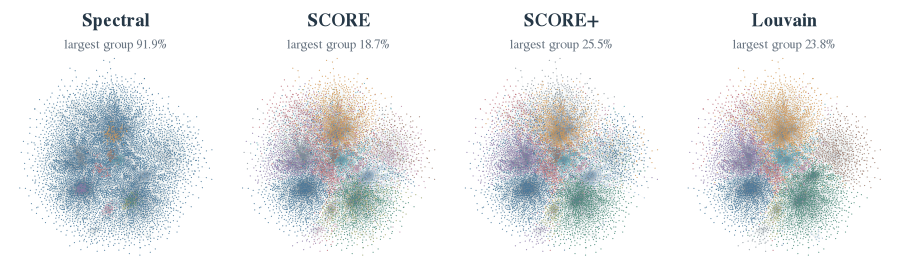

In [11]:
layout_path, meta_path = OUT / 'layout.npy', OUT / 'layout_metadata.json'
signature = hashlib.sha256(nodes.tobytes() + A.indices.tobytes() + A.indptr.tobytes()).hexdigest()
if layout_path.exists() and meta_path.exists() and json.loads(meta_path.read_text()).get('signature') == signature:
    positions = np.load(layout_path)
else:
    random.seed(SEED)
    ig.set_random_number_generator(random.Random(SEED))
    start = np.random.default_rng(SEED).normal(size=(n, 2)).tolist()
    graph_ig = ig.Graph(n=n, edges=list(zip(*sp.triu(A).nonzero())))
    positions = np.array(graph_ig.layout_fruchterman_reingold(niter=1500, seed=start).coords)
    np.save(layout_path, positions)
    meta_path.write_text(json.dumps({'signature': signature, 'seed': SEED, 'node_count': n}, indent=2))

def match_colors(labels, reference):
    # Only changes which color a community gets. The communities stay the same.
    k = max(labels.max(), reference.max()) + 1
    counts = np.zeros((k, k), dtype=int)
    np.add.at(counts, (labels, reference), 1)
    row, column = linear_sum_assignment(-counts)
    mapping = np.empty(k, dtype=int)
    mapping[row] = column
    return mapping[labels]

palette = np.array(['#48789A', '#D49A58', '#498A79', '#BD6C78', '#8C79A8', '#9B796B', '#BD8CA8', '#89939B', '#9FA76F', '#62A6B4', '#94B5CF'])
u, v = sp.triu(A, k=1).nonzero()
segments = np.stack([positions[u], positions[v]], axis=1)
low, high = positions.min(0), positions.max(0)
pad = .035 * (high - low)
fig, axs = plt.subplots(1, 4, figsize=(6.875, 1.95))
for ax, method in zip(axs, METHODS):
    colors = palette[match_colors(partitions[method], partitions['SCORE']) % len(palette)]
    ax.add_collection(LineCollection(segments, colors='#728798', linewidths=.07, alpha=.11, rasterized=True, zorder=1))
    ax.scatter(*positions.T, c=colors, s=.42, alpha=.85, linewidths=0, rasterized=True, zorder=2)
    ax.set(xlim=(low[0] - pad[0], high[0] + pad[0]), ylim=(low[1] - pad[1], high[1] + pad[1]), aspect='equal')
    ax.axis('off')
    ax.set_title(method, fontweight='bold', fontsize=10, pad=14)
    ax.text(.5, 1.015, f'largest group {np.bincount(partitions[method]).max() / n:.1%}', transform=ax.transAxes, ha='center', fontsize=7.2, color=MUTED)
fig.subplots_adjust(left=.005, right=.995, bottom=.01, top=.84, wspace=.03)
save_figure(fig, 'network_comparison')
plt.show()

## 6. Testing music similarity

**Similarity.** For users i and j, we use the Jaccard index of their artist sets: shared artists divided by all artists liked by either user.

**Contrast.** T is mean similarity within communities minus mean similarity between communities. We compute it in two ways.

- **T_eq** gives each community the same weight. This is the main statistic.
- **T_pair** gives each pair of users the same weight.

**Permutation test.** User pairs are not independent, because one user appears in thousands of pairs. So we do not use a t-test. Instead, we keep the communities fixed and shuffle whole music records between users, then recompute T. To keep the comparison fair, we shuffle only among users with similar degree and similar artist count (5 bins each).

This test assumes that music records can be exchanged within a bin. The bins only roughly control degree and activity.

In [12]:
def jaccard_matrix(features):
    x = sp.csr_matrix(features, dtype=np.float64)
    x.eliminate_zeros()
    similarity = (x @ x.T).toarray()
    counts = np.asarray(x.sum(axis=1)).ravel()
    for lo in range(0, len(counts), 512):
        block = similarity[lo:lo + 512]
        union = counts[lo:lo + 512, None] + counts[None, :] - block
        np.divide(block, union, out=block, where=union > 0)
        block[union == 0] = 0
    np.fill_diagonal(similarity, 0)
    return similarity

def onehot(labels):
    return np.eye(labels.max() + 1, dtype=np.float64)[labels]

def block_statistics(w, sizes):
    sizes = np.asarray(sizes, dtype=float)
    valid = sizes >= 2
    within = np.divide(np.diag(w), sizes * (sizes - 1), out=np.full(len(sizes), np.nan), where=valid)
    between = w / np.outer(sizes, sizes)
    same, diff = within[valid].mean(), between[np.triu_indices(len(sizes), 1)].mean()
    same_count = (sizes * (sizes - 1)).sum()
    total = sizes.sum()
    pair_same = np.trace(w) / same_count
    pair_diff = (w.sum() - np.trace(w)) / (total * (total - 1) - same_count)
    return dict(T=float(same - diff), S_same=float(same), S_diff=float(diff), ratio=float(same / diff),
                T_pair=float(pair_same - pair_diff), within=within, between=between, sizes=sizes)

def t_stat(similarity, labels):
    z = onehot(labels)
    return block_statistics(z.T @ (similarity @ z), z.sum(axis=0))

def make_strata(*variables, q=5):
    bins = [np.asarray(pd.qcut(np.asarray(v), q, labels=False, duplicates='drop'), dtype=int) for v in variables]
    return np.unique(np.column_stack(bins), axis=0, return_inverse=True)[1]

def combine_strata(*codes):
    return np.unique(np.column_stack(codes), axis=0, return_inverse=True)[1]

def summarize_null(observed, null):
    tolerance = 100 * np.finfo(float).eps * max(abs(observed), 1.)
    exceed = int(np.count_nonzero(null >= observed - tolerance))
    return dict(T=float(observed), B=len(null), exceedances=exceed, p=(1 + exceed) / (len(null) + 1),
                null_mean=float(null.mean()), null_sd=float(null.std(ddof=1)),
                null_q025=float(np.quantile(null, .025)), null_q975=float(np.quantile(null, .975)),
                excess=float(observed - null.mean()))

def perm_test(similarity, labels, strata, b, seed=SEED):
    # Shuffling community labels within bins is the same as shuffling music records.
    rng = np.random.default_rng(seed)
    groups = [np.flatnonzero(strata == s) for s in np.unique(strata)]
    z = onehot(labels)
    sizes = z.sum(axis=0)
    observed = block_statistics(z.T @ (similarity @ z), sizes)
    equal_null, pair_null = np.empty(b), np.empty(b)
    rows = np.arange(len(labels))
    for i in range(b):
        permuted = labels.copy()
        for group in groups:
            permuted[group] = labels[rng.permutation(group)]
        z.fill(0)
        z[rows, permuted] = 1
        result = block_statistics(z.T @ (similarity @ z), sizes)
        equal_null[i], pair_null[i] = result['T'], result['T_pair']
    return dict(equal=summarize_null(observed['T'], equal_null), pair=summarize_null(observed['T_pair'], pair_null))

def holm_adjust(pvalues):
    pvalues = np.asarray(pvalues, dtype=float)
    order = np.argsort(pvalues, kind='stable')
    adjusted = np.minimum(1, np.maximum.accumulate(pvalues[order] * np.arange(len(pvalues), 0, -1)))
    result = np.empty_like(adjusted)
    result[order] = adjusted
    return result

S = jaccard_matrix(X)
upper_u, upper_v = sp.triu(A, k=1).nonzero()
pair_summary = pd.DataFrame([{'All user pairs': n * (n - 1) // 2, 'Mean Jaccard, all pairs': S.sum() / (n * (n - 1)),
                              'Mean Jaccard, friends': S[upper_u, upper_v].mean()}])
save_table(pair_summary, 'pair_similarity')
STRATA_DA = make_strata(deg, n_art, q=5)
cell_sizes = np.unique(STRATA_DA, return_counts=True)[1]
print('Degree x activity bins in use:', len(cell_sizes), '| users per bin:', cell_sizes.min(), 'to', cell_sizes.max())
pair_summary

Degree x activity bins in use: 20 | users per bin: 125 to 1002


,All user pairs,"Mean Jaccard, all pairs","Mean Jaccard, friends"
0,27606165,0.062503,0.149042


In [13]:
t0 = time.time()
main_results = {m: perm_test(S, partitions[m], STRATA_DA, B_MAIN) for m in METHODS}
details = {m: t_stat(S, partitions[m]) for m in METHODS}
print(f'Main test took {time.time() - t0:.0f} seconds')

main_table = pd.DataFrame([{
    'Method': m, 'K': len(details[m]['sizes']), 'Largest community share': np.bincount(partitions[m]).max() / n,
    'S_within': details[m]['S_same'], 'S_between': details[m]['S_diff'], 'Ratio': details[m]['ratio'],
    'T_eq': main_results[m]['equal']['T'], 'Null mean': main_results[m]['equal']['null_mean'], 'Null sd': main_results[m]['equal']['null_sd'],
    'Null 2.5%': main_results[m]['equal']['null_q025'], 'Null 97.5%': main_results[m]['equal']['null_q975'],
    'Excess T_eq': main_results[m]['equal']['excess'], 'B': B_MAIN, 'Exceedances': main_results[m]['equal']['exceedances'], 'p': main_results[m]['equal']['p'],
    'T_pair': main_results[m]['pair']['T'], 'Excess T_pair': main_results[m]['pair']['excess'], 'p (T_pair)': main_results[m]['pair']['p'],
} for m in METHODS])
main_table['Holm p (4 methods)'] = holm_adjust(main_table.p)
save_table(main_table, 'main_test')
main_table.round(4)

Main test took 170 seconds


,Method,K,Largest community share,S_within,S_between,Ratio,T_eq,Null mean,Null sd,Null 2.5%,Null 97.5%,Excess T_eq,B,Exceedances,p,T_pair,Excess T_pair,p (T_pair),Holm p (4 methods)
0,Spectral,11,0.9191,0.1328,0.0860,1.5439,0.0468,0.0019,0.0004,0.0012,0.0027,0.0449,1999,0,0.0005,-0.0137,-0.0035,1.0000,0.002
1,SCORE,11,0.1872,0.0763,0.0609,1.2533,0.0154,0.0008,0.0001,0.0007,0.0009,0.0146,1999,0,0.0005,0.0163,0.0133,0.0005,0.002
2,SCORE+,11,0.2546,0.0801,0.0589,1.3599,0.0212,0.0006,0.0001,0.0005,0.0007,0.0206,1999,0,0.0005,0.0178,0.0140,0.0005,0.002
3,Louvain,11,0.2377,0.0790,0.0592,1.3337,0.0198,0.0009,0.0004,0.0003,0.0018,0.0189,1999,0,0.0005,0.0177,0.0164,0.0005,0.002


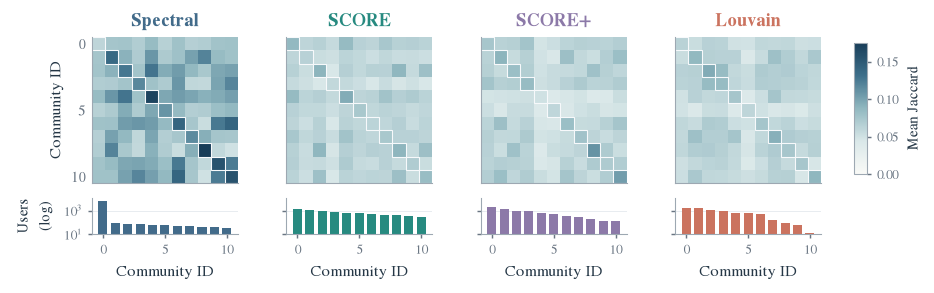

In [14]:
cmap = LinearSegmentedColormap.from_list('music', ['#FAFAF7', '#DAE8E9', '#91B8C0', '#3E708B', '#183D58'])
fig = plt.figure(figsize=(6.875, 2.2))
grid = fig.add_gridspec(2, 4, height_ratios=[4, 1], left=.06, right=.90, bottom=.17, top=.86, hspace=.16, wspace=.16)
music_max = max(np.nanmax(np.r_[details[m]['within'], details[m]['between'].ravel()]) for m in METHODS)
for j, method in enumerate(METHODS):
    block = details[method]['between'].copy()
    np.fill_diagonal(block, details[method]['within'])
    ax = fig.add_subplot(grid[0, j])
    image = ax.imshow(block, cmap=cmap, norm=Normalize(0, music_max), interpolation='nearest')
    ax.set(xticks=[], yticks=[0, 5, 10])
    ax.tick_params(length=0)
    ax.set_title(method, fontweight='bold', color=COLOR[method], fontsize=10, pad=6)
    if j == 0:
        ax.set_ylabel('Community ID')
    else:
        ax.set_yticklabels([])
    for q in range(len(block)):
        ax.add_patch(mpl.patches.Rectangle((q - .5, q - .5), 1, 1, fill=False, edgecolor='#F7F9FB', lw=.6))
    position = ax.get_position()
    size_ax = fig.add_subplot(grid[1, j])
    bar_position = size_ax.get_position()
    size_ax.set_position([position.x0, bar_position.y0, position.width, bar_position.height])
    size_ax.bar(range(len(block)), np.bincount(partitions[method]), color=COLOR[method], width=.73, edgecolor='none')
    size_ax.set(yscale='log', ylim=(10, 12000), xticks=[0, 5, 10], yticks=[10, 1000], xlabel='Community ID')
    size_ax.tick_params(labelsize=7, length=2)
    if j == 0:
        size_ax.set_ylabel('Users\n(log)', fontsize=8)
    else:
        size_ax.set_yticklabels([])
    y_grid(size_ax)
cax = fig.add_axes([.925, .38, .014, .46])
cb = fig.colorbar(image, cax=cax)
cb.ax.tick_params(labelsize=7, length=2)
cb.set_label('Mean Jaccard', fontsize=8, labelpad=5)
save_figure(fig, 'community_music')
plt.show()

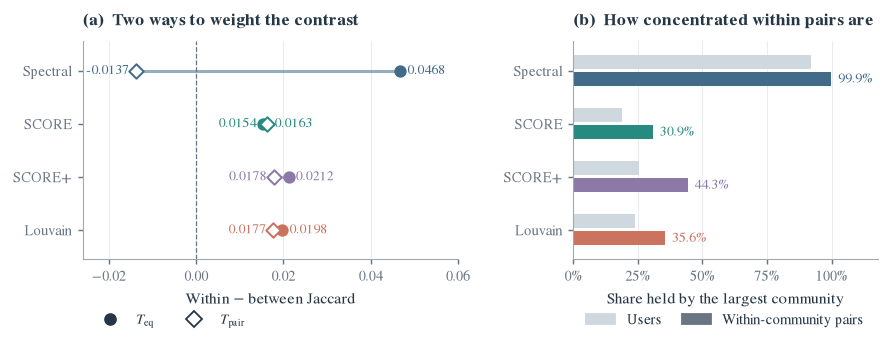

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(6.875, 2.7), gridspec_kw={'width_ratios': [1.23, 1]})
top_y = len(METHODS) - 1
for j, method in enumerate(METHODS):
    y = top_y - j
    color = COLOR[method]
    eq, pair = details[method]['T'], details[method]['T_pair']
    axs[0].plot([eq, pair], [y, y], color=color, lw=1.7, alpha=.55)
    axs[0].scatter(eq, y, s=34, color=color, zorder=4)
    axs[0].scatter(pair, y, s=32, facecolor='white', edgecolor=color, linewidth=1.1, marker='D', zorder=5)
    # The two points of balanced methods are close, so put their numbers on opposite sides.
    left, right = (eq, pair) if eq < pair else (pair, eq)
    axs[0].text(left - .0016, y, f'{left:.4f}', ha='right', va='center', fontsize=7.6, color=color)
    axs[0].text(right + .0016, y, f'{right:.4f}', ha='left', va='center', fontsize=7.6, color=color)
    sizes = np.bincount(partitions[method])
    share_users = sizes.max() / n
    share_pairs = (sizes * (sizes - 1)).max() / np.sum(sizes * (sizes - 1))
    axs[1].barh(y + .16, share_users, color='#D0D8DF', height=.26)
    axs[1].barh(y - .16, share_pairs, color=color, height=.26)
    axs[1].text(share_pairs + .025, y - .16, f'{share_pairs:.1%}', va='center', fontsize=7.6, color=color)
axs[0].axvline(0, color=MUTED, ls='--', lw=.7)
axs[0].set(xlim=(-.026, .060), ylim=(-.55, top_y + .55), yticks=list(range(top_y, -1, -1)), yticklabels=METHODS, xlabel='Within − between Jaccard')
axs[1].set(xlim=(0, 1.18), ylim=(-.55, top_y + .55), yticks=list(range(top_y, -1, -1)), yticklabels=METHODS, xlabel='Share held by the largest community')
axs[1].xaxis.set_major_formatter(PercentFormatter(1))
axs[1].set_xticks([0, .25, .5, .75, 1])
panel_title(axs[0], 'a', 'Two ways to weight the contrast')
panel_title(axs[1], 'b', 'How concentrated within pairs are')
axs[0].legend(handles=[Line2D([], [], marker='o', ls='', color=INK, label=r'$T_{\rm eq}$'),
                       Line2D([], [], marker='D', ls='', color=INK, markerfacecolor='white', label=r'$T_{\rm pair}$')],
              loc='upper left', bbox_to_anchor=(0, -.19), ncol=2, frameon=False, columnspacing=1.7)
axs[1].legend(handles=[mpl.patches.Patch(color='#D0D8DF', label='Users'), mpl.patches.Patch(color=MUTED, label='Within-community pairs')],
              loc='upper left', bbox_to_anchor=(0, -.19), ncol=2, frameon=False, columnspacing=1.4)
for ax in axs:
    x_grid(ax)
fig.subplots_adjust(left=.09, right=.98, top=.88, bottom=.26, wspace=.34)
save_figure(fig, 'music_weighting')
plt.show()

## 7. Is it only because of country?

People from the same country may follow each other and like the same local artists. If so, communities might only be a proxy for country.

To check this, we shuffle music records **only within a country**. Any similarity that comes from sharing a country stays in the shuffled data. If the real T is still higher, then communities show something extra.

We run two versions: country only, and country × degree × activity (3 bins each). Each uses 199 shuffles, so the smallest possible p-value is 0.005.

The share "null mean / T" is descriptive. It is not a causal share explained by country.

In [16]:
STRATA_C = pd.factorize(country)[0]
STRATA_CDA = combine_strata(STRATA_C, make_strata(deg, n_art, q=3))
country_results = {m: perm_test(S, partitions[m], STRATA_C, B_CHECK, seed=SEED + 1) for m in METHODS}
joint_results = {m: perm_test(S, partitions[m], STRATA_CDA, B_CHECK, seed=SEED + 2) for m in METHODS}
country_table = pd.DataFrame([{
    'Method': m, 'NMI with country': NMI(country, partitions[m]), 'T_eq': country_results[m]['equal']['T'],
    'Country null mean': country_results[m]['equal']['null_mean'],
    'Share reproduced': country_results[m]['equal']['null_mean'] / country_results[m]['equal']['T'],
    'Country excess': country_results[m]['equal']['excess'], 'Country p': country_results[m]['equal']['p'],
    'Joint null mean': joint_results[m]['equal']['null_mean'],
    'Joint excess': joint_results[m]['equal']['excess'], 'Joint p': joint_results[m]['equal']['p'],
    'T_pair': country_results[m]['pair']['T'], 'Country excess (T_pair)': country_results[m]['pair']['excess'],
    'Joint excess (T_pair)': joint_results[m]['pair']['excess'], 'Joint p (T_pair)': joint_results[m]['pair']['p'],
} for m in METHODS])
save_table(country_table, 'country_check')
country_table.round(4)

,Method,NMI with country,T_eq,Country null mean,Share reproduced,Country excess,Country p,Joint null mean,Joint excess,Joint p,T_pair,Country excess (T_pair),Joint excess (T_pair),Joint p (T_pair)
0,Spectral,0.1403,0.0468,0.0175,0.3746,0.0293,0.005,0.0277,0.0191,0.005,-0.0137,-0.0138,-0.0024,1.000
1,SCORE,0.5071,0.0154,0.0100,0.6482,0.0054,0.005,0.0108,0.0047,0.005,0.0163,0.0058,0.0040,0.005
2,SCORE+,0.5245,0.0212,0.0110,0.5200,0.0102,0.005,0.0118,0.0094,0.005,0.0178,0.0063,0.0050,0.005
3,Louvain,0.6347,0.0198,0.0141,0.7155,0.0056,0.005,0.0161,0.0036,0.010,0.0177,0.0052,0.0036,0.005


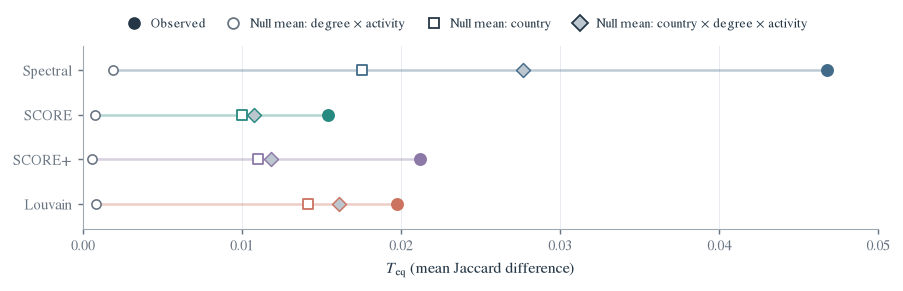

In [17]:
fig, ax = plt.subplots(figsize=(6.875, 2.1))
top_y = len(METHODS) - 1
for j, method in enumerate(METHODS):
    y = top_y - j
    color = COLOR[method]
    da = main_results[method]['equal']['null_mean']
    cn = country_results[method]['equal']['null_mean']
    jn = joint_results[method]['equal']['null_mean']
    observed = main_results[method]['equal']['T']
    ax.plot([da, observed], [y, y], color=color, lw=1.4, alpha=.35, zorder=1)
    ax.scatter(da, y, s=26, facecolor='white', edgecolor=MUTED, linewidth=.9, marker='o', zorder=3)
    ax.scatter(cn, y, s=28, facecolor='white', edgecolor=color, linewidth=1, marker='s', zorder=3)
    ax.scatter(jn, y, s=30, color=NEUTRAL, edgecolor=color, linewidth=.8, marker='D', zorder=3)
    ax.scatter(observed, y, s=38, color=color, zorder=4)
ax.set(yticks=list(range(top_y, -1, -1)), yticklabels=METHODS, ylim=(-.55, top_y + .55), xlim=(0, .05), xlabel=r'$T_{\rm eq}$ (mean Jaccard difference)')
x_grid(ax)
ax.legend(handles=[Line2D([], [], marker='o', ls='', color=INK, label='Observed'),
                   Line2D([], [], marker='o', ls='', color=MUTED, markerfacecolor='white', label='Null mean: degree × activity'),
                   Line2D([], [], marker='s', ls='', color=INK, markerfacecolor='white', label='Null mean: country'),
                   Line2D([], [], marker='D', ls='', color=INK, markerfacecolor=NEUTRAL, label='Null mean: country × degree × activity')],
          loc='upper center', bbox_to_anchor=(.48, 1.22), ncol=4, frameon=False, columnspacing=1.1, handletextpad=.2, fontsize=7.4)
fig.subplots_adjust(left=.09, right=.98, top=.87, bottom=.2)
save_figure(fig, 'country_check')
plt.show()

## 8. Sensitivity checks

We change one choice at a time and see if the main results change. Communities are refit when K, τ or γ changes. They stay fixed when we remove popular artists.

Removing popular artists changes the Jaccard scale for everyone. So the ratio can go up while the actual difference goes down. We report both.

In [18]:
t0 = time.time()
sensitivity = []
def check(kind, setting, method, labels, similarity=S, **more):
    result = perm_test(similarity, labels, STRATA_DA, B_CHECK, seed=SEED + 7)
    detail = t_stat(similarity, labels)
    sensitivity.append({'check': kind, 'setting': setting, 'method': method, 'K': labels.max() + 1, 'T_eq': detail['T'], 'T_pair': detail['T_pair'],
                        'Ratio': detail['ratio'], 'Excess T_eq': result['equal']['excess'], 'p': result['equal']['p'], 'B': B_CHECK, **more})

for k in sorted({5, 8, K, 15, 20}):
    check('K', k, 'Spectral', spectral_labels(vecs_A, k))
    check('K', k, 'SCORE', score_labels(vecs_A, k))
    check('K', k, 'SCORE+', scoreplus_labels(vals_L, vecs_L, k))
    check('K', k, UNCLIPPED, scoreplus_labels(vals_L, vecs_L, k, clip=False))
for gamma in [.1, .3, .5, 1.]:
    check('gamma', gamma, 'Louvain', louvain_labels(G, gamma))
for name, tau in [('0.3 x mean degree', .3 * deg.mean()), ('mean degree', deg.mean()), ('3 x mean degree', 3 * deg.mean()), ('0.1 x max degree', .1 * deg.max())]:
    v, V = leading_eigs(reg_laplacian(A, tau), 25)
    check('tau', name, 'SCORE+', scoreplus_labels(v, V, K))
    check('tau', name, UNCLIPPED, scoreplus_labels(v, V, K, clip=False))

order = np.argsort(-art_pop)
for fraction in [.01, .05, .10]:
    drop = order[:int(np.ceil(fraction * X.shape[1]))]
    keep = np.setdiff1d(np.arange(X.shape[1]), drop)
    S_kept = jaccard_matrix(X[:, keep])
    empty = int(np.sum(np.asarray(X[:, keep].sum(1)).ravel() == 0))
    for method, labels in all_labels.items():
        check('popular artists removed', f'top {int(fraction * 100)}%', method, labels, similarity=S_kept, artists_kept=len(keep), users_with_no_artists=empty)
    del S_kept

sensitivity_table = pd.DataFrame(sensitivity)
save_table(sensitivity_table, 'sensitivity')
print(f'Sensitivity checks took {time.time() - t0:.0f} seconds')

version_rows = []
for name, vals, vecs in [('mean degree', vals_L, vecs_L), ('0.1 x max degree', vals_max, vecs_max)]:
    m = scoreplus_M(vals, K)
    ratios = score_ratios(vecs[:, :m] * vals[:m], m, clip=False)
    for clip in [True, False]:
        labels = scoreplus_labels(vals, vecs, K, clip=clip)
        detail = t_stat(S, labels)
        version_rows.append({'tau': name, 'Clipped': clip, 'M': m, 'Share of ratios above log n': np.mean(np.abs(ratios) > LOG_N), 'Largest absolute ratio': np.abs(ratios).max(),
                             'Smallest community': np.bincount(labels).min(), 'Largest community': np.bincount(labels).max(),
                             'Largest share': np.bincount(labels).max() / n, 'T_eq': detail['T'], 'Ratio': detail['ratio'], 'T_pair': detail['T_pair']})
version_table = pd.DataFrame(version_rows)
save_table(version_table, 'scoreplus_versions')
version_table.round(4)

Sensitivity checks took 230 seconds


,tau,Clipped,M,Share of ratios above log n,Largest absolute ratio,Smallest community,Largest community,Largest share,T_eq,Ratio,T_pair
0,mean degree,True,12,0.0723,1096.2139,138,1892,0.2546,0.0212,1.3599,0.0178
1,mean degree,False,12,0.0723,1096.2139,6,4651,0.6259,0.0553,2.1341,0.0112
2,0.1 x max degree,True,12,0.1848,5263.1367,126,1509,0.2031,0.0228,1.3767,0.0181
3,0.1 x max degree,False,12,0.1848,5263.1367,5,4868,0.6551,0.0242,1.4324,0.0089


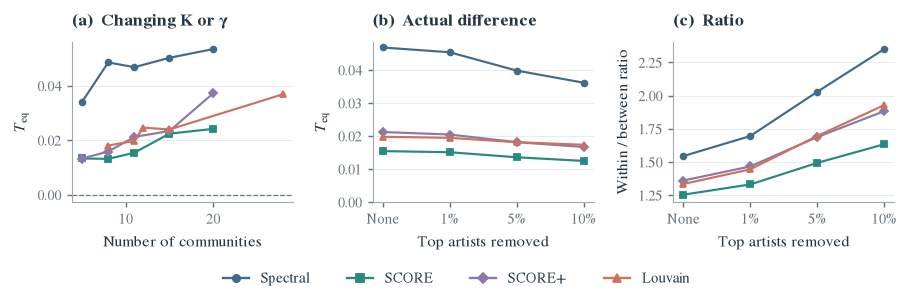

In [19]:
fig, axs = plt.subplots(1, 3, figsize=(6.875, 2.2))
base = main_table.set_index('Method')
for method in METHODS[:3]:
    rows = sensitivity_table[(sensitivity_table.check == 'K') & (sensitivity_table.method == method)]
    axs[0].plot(rows.K, rows.T_eq, f'-{MARKER[method]}', color=COLOR[method], ms=3.2, lw=1.2)
rows = pd.concat([sensitivity_table[sensitivity_table.check == 'gamma'][['K', 'T_eq']],
                  pd.DataFrame({'K': [base.loc['Louvain', 'K']], 'T_eq': [base.loc['Louvain', 'T_eq']]})]).sort_values('K')
axs[0].plot(rows.K, rows.T_eq, f'-{MARKER["Louvain"]}', color=COLOR['Louvain'], ms=3.2, lw=1.2)
axs[0].axhline(0, color=MUTED, ls='--', lw=.7)
axs[0].set(xlabel='Number of communities', ylabel=r'$T_{\rm eq}$')
panel_title(axs[0], 'a', 'Changing K or γ')

steps = ['None', '1%', '5%', '10%']
removed = sensitivity_table[sensitivity_table.check == 'popular artists removed']
for method in METHODS:
    rows = removed[removed.method == method]
    axs[1].plot(steps, [base.loc[method, 'T_eq'], *rows.T_eq], f'-{MARKER[method]}', color=COLOR[method], ms=3.2, lw=1.2)
    axs[2].plot(steps, [base.loc[method, 'Ratio'], *rows.Ratio], f'-{MARKER[method]}', color=COLOR[method], ms=3.2, lw=1.2)
axs[1].set(xlabel='Top artists removed', ylabel=r'$T_{\rm eq}$', ylim=(0, None))
axs[2].set(xlabel='Top artists removed', ylabel='Within / between ratio')
panel_title(axs[1], 'b', 'Actual difference')
panel_title(axs[2], 'c', 'Ratio')
for ax in axs:
    y_grid(ax)
method_legend(fig, y=-.03)
fig.subplots_adjust(left=.07, right=.99, top=.87, bottom=.31, wspace=.36)
save_figure(fig, 'sensitivity')
plt.show()

## 9. Summary

- The four methods give very different community sizes, but all have a positive T_eq.
- Spectral has the largest T_eq, but its T_pair is negative. Almost all of its within-community pairs come from one huge group.
- For the three balanced methods, both T_eq and T_pair are positive.
- Shuffling within country reproduces a large part of the contrast, but not all of it.

These are associations. They do not show that social ties cause similar taste, or that similar taste causes social ties. This analysis was also done after looking at the data, so it is exploratory.

In [20]:
display(main_table[['Method', 'Largest community share', 'Ratio', 'T_eq', 'Excess T_eq', 'p', 'Holm p (4 methods)', 'T_pair']].round(4))
print('Files saved in', OUT.relative_to(ROOT))
print(sorted(p.name for p in FIG.glob('*.pdf')))
print(sorted(p.name for p in TAB.glob('*.csv')))

,Method,Largest community share,Ratio,T_eq,Excess T_eq,p,Holm p (4 methods),T_pair
0,Spectral,0.9191,1.5439,0.0468,0.0449,0.0005,0.002,-0.0137
1,SCORE,0.1872,1.2533,0.0154,0.0146,0.0005,0.002,0.0163
2,SCORE+,0.2546,1.3599,0.0212,0.0206,0.0005,0.002,0.0178
3,Louvain,0.2377,1.3337,0.0198,0.0189,0.0005,0.002,0.0177


Files saved in output
['community_music.pdf', 'country_check.pdf', 'localization.pdf', 'music_weighting.pdf', 'network_comparison.pdf', 'sensitivity.pdf', 'study_diagnostics.pdf']
['clipping_summary.csv', 'community_balance.csv', 'community_sizes.csv', 'country_check.csv', 'data_summary.csv', 'first_eigenvector.csv', 'k_selection.csv', 'localization_by_degree.csv', 'louvain_resolution.csv', 'main_test.csv', 'nmi_matrix.csv', 'pair_similarity.csv', 'scoreplus_versions.csv', 'sensitivity.csv']
